## Project Description

This project aims to predict whether an album will reach the Top 10 on the Billboard 200 based on its early chart performance and other factors that may influence its success. Using historical chart data, the model will learn patterns and use them to predict the potential chart success of albums.

The idea for this project came from my unhealthy habit of listening to music and my curiosity about why some genuinely great albums fail to make it onto the charts, while others achieve huge success. I wanted to explore whether machine learning could help uncover patterns behind this and predict an album's potential chart performance using historical data and other relevant factors.

The project will start by analysing early chart performance and will later explore additional factors, such as Spotify audio features and an artist's previous chart history, to see whether they improve the predictions:)

In [1]:
# importing libraries for data analysis and visualisation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the Billboard 200 dataset
df = pd.read_csv("billboard-200-current.csv")

# Display the first five rows
df.head()

,chart_week,current_week,title,performer,last_week,peak_pos,wks_on_chart,wks_at_no1
0,2021-01-02,1,Evermore,Taylor Swift,1,1,2,NaN
1,2021-01-02,2,McCartney III,Paul McCartney,0,2,1,NaN
2,2021-01-02,3,Music To Be Murdered By,Eminem,199,1,48,NaN
3,2021-01-02,4,Christmas,Michael Buble,4,1,90,NaN
4,2021-01-02,5,Merry Christmas,Mariah Carey,10,3,99,NaN


### understanding the dataset
#### before building this model, we need to understand how much data we have, what columns are available and which columns contain missing values.

In [2]:
# display the number of rows and columns
print(df.shape)

# display all column names
print("\ncolumns in the dataset:")
print(df.columns.tolist())

# display data types and non-null counts
print("\ndataset information:")
df.info()

# generating descriptive statistics
print("\ndataset summary:")
display(df.describe(include="all"))

(620591, 8)

columns in the dataset:
['chart_week', 'current_week', 'title', 'performer', 'last_week', 'peak_pos', 'wks_on_chart', 'wks_at_no1']

dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 620591 entries, 0 to 620590
Data columns (total 8 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   chart_week    620591 non-null  object 
 1   current_week  620591 non-null  int64  
 2   title         620534 non-null  object 
 3   performer     620591 non-null  object 
 4   last_week     620591 non-null  int64  
 5   peak_pos      620591 non-null  int64  
 6   wks_on_chart  620591 non-null  int64  
 7   wks_at_no1    1 non-null       float64
dtypes: float64(1), int64(4), object(3)
memory usage: 37.9+ MB

dataset summary:


,chart_week,current_week,title,performer,last_week,peak_pos,wks_on_chart,wks_at_no1
count,620591,620591.000000,620534,620591,620591.000000,620591.000000,620591.000000,1.0
unique,3104,NaN,34707,10188,NaN,NaN,NaN,NaN
top,2021-01-02,NaN,Greatest Hits,Soundtrack,NaN,NaN,NaN,NaN
freq,200,NaN,9248,24944,NaN,NaN,NaN,NaN
mean,NaN,100.465123,NaN,NaN,85.504171,40.191300,45.346845,1.0
std,NaN,57.720854,NaN,NaN,59.197197,49.817471,89.091139,NaN
min,NaN,1.000000,NaN,NaN,0.000000,1.000000,1.000000,1.0
25%,NaN,50.000000,NaN,NaN,33.000000,3.000000,6.000000,1.0
50%,NaN,100.000000,NaN,NaN,83.000000,17.000000,16.000000,1.0
75%,NaN,150.000000,NaN,NaN,135.000000,60.000000,42.000000,1.0


In [3]:
# making a copy so the original dataset remains unchanged
df = df.copy()

# convert chart dates into datetime format
df["chart_week"] = pd.to_datetime(df["chart_week"], errors="coerce")

# Convert numerical columns into numeric data types
numeric_cols = [
    "current_week",
    "last_week",
    "peak_pos",
    "wks_on_chart",
    "wks_at_no1"
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows missing essential information
df = df.dropna(
    subset=["chart_week", "title", "performer", "current_week", "wks_on_chart"]
)

# Remove extra spaces from album titles and artist names
df["title"] = df["title"].astype(str).str.strip()
df["performer"] = df["performer"].astype(str).str.strip()

# Keep valid Billboard 200 chart positions and positive chart-week counts
df = df[
    df["current_week"].between(1, 200)
    & (df["wks_on_chart"] >= 1)
]

# Remove duplicate album entries for the same chart date
df = df.drop_duplicates(
    subset=["chart_week", "title", "performer"]
)

# Sort the data by album and date
df = df.sort_values(
    ["title", "performer", "chart_week"]
).reset_index(drop=True)

# Display the cleaned dataset information
print("Cleaned dataset shape:", df.shape)
print("\nMissing values:")
print(df.isna().sum())

## Here, current_week represents an album's chart position, while wks_on_chart tells us how many weeks it has spent on the chart.
## We'll use both to reconstruct each album's early chart trajectory.

Cleaned dataset shape: (620439, 8)

Missing values:
chart_week           0
current_week         0
title                0
performer            0
last_week            0
peak_pos             0
wks_on_chart         0
wks_at_no1      620438
dtype: int64


In [4]:
# Display the date range of the dataset
print("First chart date:", df["chart_week"].min())
print("Last chart date:", df["chart_week"].max())

# count unique album and artist combinations
print(
    "Unique album-artist pairs:",
    df[["title", "performer"]].drop_duplicates().shape[0]
)

# count unique artists
print("Unique artists:", df["performer"].nunique())

# display the most frequently recorded album-artist pairs
album_counts = (
    df.groupby(["title", "performer"])
      .size()
      .sort_values(ascending=False)
)

print("\nAlbums with the most chart entries:")
display(album_counts.head(10))

First chart date: 1967-04-15 00:00:00
Last chart date: 2026-09-26 00:00:00
Unique album-artist pairs: 38295
Unique artists: 10187

Albums with the most chart entries:


title                      performer                 
The Dark Side Of The Moon  Pink Floyd                    996
Journey's Greatest Hits    Journey                       927
Metallica                  Metallica                     849
Legend: The Best Of...     Bob Marley And The Wailers    812
Curtain Call: The Hits     Eminem                        806
Doo-Wops & Hooligans       Bruno Mars                    798
Nevermind                  Nirvana                       792
Greatest Hits              Guns N' Roses                 791
Thriller                   Michael Jackson               736
good kid, m.A.A.d city     Kendrick Lamar                725
dtype: int64

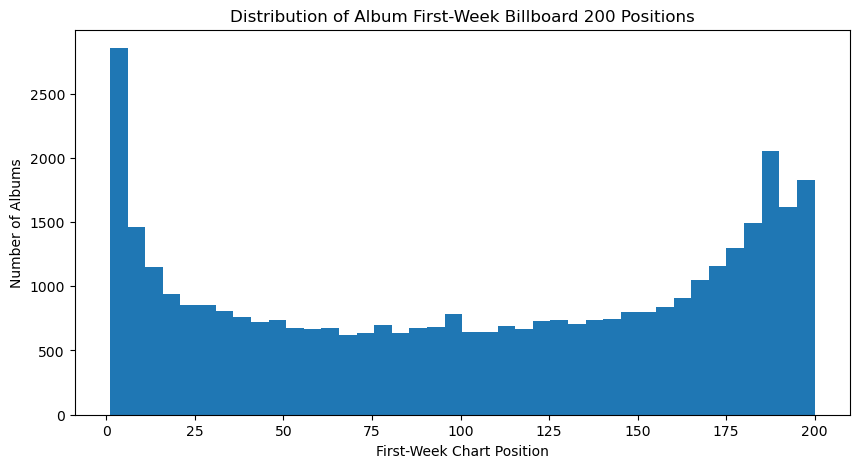

In [5]:
##since this is a prediction model, starting with something simple but significant in the long run; how albums perform  during their first four weeks.
## For example, we can look at the distribution of their first-week position.
# get each album's first recorded chart position
first_week = (
    df[df["wks_on_chart"] == 1]
    .groupby(["title", "performer"])["current_week"]
    .first()
)

# Plot the distribution of first-week chart positions
plt.figure(figsize=(10, 5))

plt.hist(first_week, bins=40)

plt.title("Distribution of Album First-Week Billboard 200 Positions")
plt.xlabel("First-Week Chart Position")
plt.ylabel("Number of Albums")

plt.show()

In [6]:
##for this project we're ultimately asking: can we predict whether an album will reach the Top 10 based on its early performance?
## so we'll use a graph that compares first-week position with eventual Top-10 status.
# get each album's first-week chart position
first_week = (
    df[df["wks_on_chart"] == 1]
    .groupby(["title", "performer"])["current_week"]
    .first()
    .rename("first_week_rank")
)

# get each album's best chart position during its time on the billboard 200
best_rank = (
    df.groupby(["title", "performer"])["current_week"]
    .min()
    .rename("best_rank")
)

# Combine the first-week position and best position
album_summary = pd.concat(
    [first_week, best_rank],
    axis=1
).dropna()

# create our target:
# True = album eventually reached the Top 10
# False = album did not reach the Top 10
album_summary["top_10"] = album_summary["best_rank"] <= 10

album_summary.head()

,,first_week_rank,best_rank,top_10
title,performer,,,
!,Trippie Redd,3.0,3,True
!Viva El Amor!,Pretenders,158.0,158,False
!Viva La Cobra!,Cobra Starship,80.0,80,False
# 1's,Mariah Carey,4.0,4,True
#1,Sonny James,200.0,187,False


In [7]:
# this counts how many albums reached the Top 10
# and how many did not

print("Albums that reached the Top 10:")
print(album_summary["top_10"].value_counts())

print("\nPercentage of albums in each group:")
print(
    album_summary["top_10"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Albums that reached the Top 10:
top_10
False    32290
True      5729
Name: count, dtype: int64

Percentage of albums in each group:
top_10
False    84.93
True     15.07
Name: proportion, dtype: float64


## this result tells us that:
- 32,290 albums (84.93%) did not reach the Top 10.
- 5,729 albums (15.07%) did reach the Top 10.
so our target is quite imbalanced: roughly 85% negative vs. 15% positive.
## Why this matters
if we ignored the imbalance, a lazy model could simply say:
"no album will reach the Top 10" which would make this whole analysis pointless and it would be 84.93% accurate, despite being completely useless for our actual question.
so before i train anything, let's see whether first-week performance is actually different between 
the two groups.

In [8]:
# creating groups based on where an album debuted in its first week
album_summary["first_week_group"] = pd.cut(
    album_summary["first_week_rank"],
    bins=[0, 10, 25, 50, 100, 150, 200],
    labels=[
        "1–10",
        "11–25",
        "26–50",
        "51–100",
        "101–150",
        "151–200"
    ]
)

album_summary.head()

,,first_week_rank,best_rank,top_10,first_week_group
title,performer,,,,
!,Trippie Redd,3.0,3,True,1–10
!Viva El Amor!,Pretenders,158.0,158,False,151–200
!Viva La Cobra!,Cobra Starship,80.0,80,False,51–100
# 1's,Mariah Carey,4.0,4,True,1–10
#1,Sonny James,200.0,187,False,151–200


In [9]:
# calculate the percentage of albums that eventually reached the Top 10
top10_by_group = (
    album_summary
    .groupby("first_week_group", observed=False)["top_10"]
    .mean()
    .mul(100)
)

top10_by_group


first_week_group
1–10       100.000000
11–25        8.522920
26–50        7.297576
51–100       6.348265
101–150      3.059786
151–200      1.801180
Name: top_10, dtype: float64

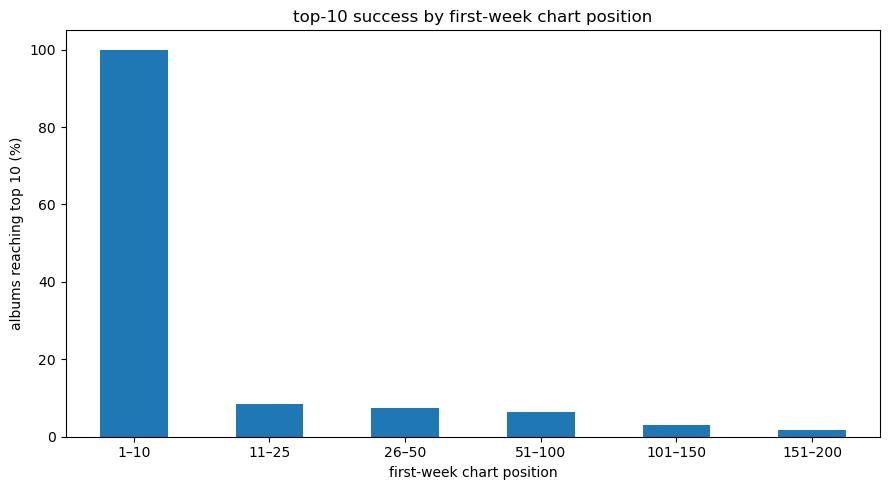

In [10]:
plt.figure(figsize=(9, 5))

top10_by_group.plot(kind="bar")

plt.title("top-10 success by first-week chart position")
plt.xlabel("first-week chart position")
plt.ylabel("albums reaching top 10 (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### preparing the data for prediction
now that i've looked at how an album's first-week position relates to its success, i'll look at its performance over the first four weeks.
this will help me see whether an album's early chart movement can help predict if it will eventually reach the top 10.

In [11]:
# identify each album using its title and artist
album_id = ["title", "performer"]

# keep only the first four weeks of each album's chart run
early_weeks = df[df["wks_on_chart"].isin([1, 2, 3, 4])].copy()

# create one row per album, with a separate column for each week
early_pivot = early_weeks.pivot_table(
    index=album_id,
    columns="wks_on_chart",
    values="current_week",
    aggfunc="first"
)

# give the columns clearer names
early_pivot.columns = [
    f"rank_week_{int(week)}"
    for week in early_pivot.columns
]

# make sure all four week columns exist
for week in range(1, 5):
    column = f"rank_week_{week}"

    if column not in early_pivot.columns:
        early_pivot[column] = np.nan

# keep albums with data for all four weeks
rank_cols = [f"rank_week_{week}" for week in range(1, 5)]
early_pivot = early_pivot.dropna(subset=rank_cols)

# create additional features from the first four weeks
early_pivot["best_early_rank"] = early_pivot[rank_cols].min(axis=1)

early_pivot["average_early_rank"] = early_pivot[rank_cols].mean(axis=1)

# positive values mean the album moved closer to #1
early_pivot["rank_improvement"] = (
    early_pivot["rank_week_1"] - early_pivot["rank_week_4"]
)

display(early_pivot.head())
print("Albums with four weeks of chart data:", len(early_pivot))


,,rank_week_1,rank_week_2,rank_week_3,rank_week_4,best_early_rank,average_early_rank,rank_improvement
title,performer,,,,,,,
!,Trippie Redd,3.0,31.0,53.0,66.0,3.0,38.25,-63.0
# 1's,Mariah Carey,4.0,7.0,7.0,6.0,4.0,6.00,-2.0
#1,Sonny James,200.0,198.0,187.0,189.0,187.0,193.50,11.0
#1 Girl,Mindless Behavior,7.0,27.0,35.0,45.0,7.0,28.50,-38.0
#1 To Infinity,Mariah Carey,29.0,58.0,92.0,143.0,29.0,80.50,-114.0


Albums with four weeks of chart data: 24128


### Identifying Albums That Reached the Top 10
next, lets identify which albums eventually reached the billboard 200 Top 10.
which i believe will give the model a target to learn from using each album's first four weeks of chart performance.

### splitting the data
 using older albums to train the model and newer albums to test it. which will help me see how well it predicts top-10 success on albums it hasn't seen before.

In [12]:
# features available during the first four weeks
feature_cols = [
    "rank_week_1",
    "rank_week_2",
    "rank_week_3",
    "rank_week_4",
    "best_early_rank",
    "average_early_rank",
    "rank_improvement"
]

# sort albums by debut date to keep the split chronological
model_df = model_df.sort_values("debut_date").copy()

# use the earlier 80% of albums for training and the later 20% for testing
split_date = model_df["debut_date"].quantile(0.8)

train_df = model_df[model_df["debut_date"] < split_date].copy()
test_df = model_df[model_df["debut_date"] >= split_date].copy()

X_train = train_df[feature_cols]
y_train = train_df["top_10"]

X_test = test_df[feature_cols]
y_test = test_df["top_10"]

print("Training albums:", len(train_df))
print("Testing albums:", len(test_df))

print("\nTraining target percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target percentages:")
print((y_test.value_counts(normalize=True) * 100).round(2))


NameError: name 'model_df' is not defined

### creating the target

now that i've created features from each album's first four weeks, i'll check whether it reaches the top 10 in a later chart week. this will be the outcome the model learns to predict, using only the album's early chart performance as its input.

In [ ]:
# find each album's best chart position after its first four weeks
later_weeks = df[df["wks_on_chart"] > 4]

later_best_rank = (
    later_weeks.groupby(["title", "performer"])["current_week"]
    .min()
    .rename("later_best_rank")
)

# add the later chart results to our first-four-weeks features
model_df = early_pivot.join(later_best_rank)

# create the target: 1 if the album reached the Top 10 after week 4
model_df["top_10"] = (
    model_df["later_best_rank"].le(10)
).astype(int)

# Add each album's debut date
album_debut = (
    df.groupby(["title", "performer"])["chart_week"]
    .min()
    .rename("debut_date")
)

model_df = model_df.join(album_debut)

# Keep albums with at least 52 weeks of follow-up time
latest_date = df["chart_week"].max()
cutoff_date = latest_date - pd.Timedelta(weeks=52)

model_df = model_df[
    model_df["debut_date"] <= cutoff_date
].copy()

# Check the updated data
print("Number of albums:", len(model_df))

print("\nTarget counts:")
print(model_df["top_10"].value_counts())

print("\nTarget percentages:")
print(
    (model_df["top_10"].value_counts(normalize=True) * 100).round(2)
)

display(model_df.head())


### Understanding the Target

After updating the target, 2,283 albums (9.5%) reached the Top 10 after their first four chart weeks, while 21,756 (90.5%) had no recorded Top 10 position in the later chart weeks. This gives the model a clear outcome to predict using each album's early chart performance.

In [ ]:
feature_cols = [
    "rank_week_1",
    "rank_week_2",
    "rank_week_3",
    "rank_week_4",
    "best_early_rank",
    "average_early_rank",
    "rank_improvement"
]

model_df = model_df.sort_values("debut_date").copy()

# use the 80th percentile of debut dates as the split point
split_date = model_df["debut_date"].quantile(0.8)

# earlier albums are used for training; later albums for testing
train_df = model_df[model_df["debut_date"] < split_date].copy()
test_df = model_df[model_df["debut_date"] >= split_date].copy()

# separate the input features from the target
X_train = train_df[feature_cols]
y_train = train_df["top_10"]

X_test = test_df[feature_cols]
y_test = test_df["top_10"]

print("Training albums:", len(train_df))
print("Testing albums:", len(test_df))

print("\nTraining target percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target percentages:")
print((y_test.value_counts(normalize=True) * 100).round(2))


### splitting the data

i split the albums chronologically, using 80% for training and 20% for testing. the model will learn patterns from earlier albums and then make predictions on later albums. both sets have a similar proportion of albums that reached the Top 10 after their first four weeks.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# create the Logistic Regression model
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# trains the model on the training data
logistic_model.fit(X_train, y_train)

# predict whether each test album will reach the Top 10
y_pred = logistic_model.predict(X_test)

# get the predicted probability of reaching the Top 10
y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("Logistic Regression training complete!")


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# measures the model's performance
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 3))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))

# shows performance for each outcome
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Did not reach Top 10", "Reached Top 10"],
    zero_division=0
))

# show correct and incorrect predictions
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Did not reach Top 10", "Reached Top 10"],
    values_format="d"
)

plt.title("Logistic Regression: Confusion Matrix")
plt.tight_layout()
plt.show()


### evaluating logistic regression

the logistic regression model achieved 81.5% accuracy and 90.9% recall. this means it identified most albums that reached the top 10 after their first four weeks, but its precision of 34.2% shows that many of its positive predictions were incorrect. the results suggest that the model can identify potential successes, but there is room to improve the accuracy of its predictions.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# creates the random forest model
forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)

# trains the model
forest_model.fit(X_train, y_train)

# Predict the test outcomes and their probabilities
forest_pred = forest_model.predict(X_test)
forest_prob = forest_model.predict_proba(X_test)[:, 1]

print("random forest training complete!")


In [ ]:
# evaluating the random forest model

print("Accuracy:", round(accuracy_score(y_test, forest_pred), 3))
print("Precision:", round(precision_score(y_test, forest_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, forest_pred, zero_division=0), 3))
print("F1-score:", round(f1_score(y_test, forest_pred, zero_division=0), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, forest_prob), 3))

# a more detailed breakdown of the results
print("\nClassification Report:")
print(classification_report(
    y_test,
    forest_pred,
    target_names=["Did not reach Top 10", "Reached Top 10"],
    zero_division=0
))

# displays the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    forest_pred,
    display_labels=["Did not reach Top 10", "Reached Top 10"],
    values_format="d"
)

plt.title("random forest: confusion matrix")
plt.tight_layout()
plt.show()

In [ ]:
# checking the features used by the model
print("Features used by Random Forest:")
print(X_train.columns.tolist())

# Check the original feature table
print("\nFirst few rows of the training features:")
display(X_train.head())

### since our random forest has finished evaluating and training, our next step is to check what features influenced our model the most

In [ ]:
# importance of each feature
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": forest_model.feature_importances_
})

# sorts features from most important to least important
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# display the results
display(importance_df)

plt.figure(figsize=(9, 5))
plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)
plt.xlabel("Importance")
plt.title("Random Forest: Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

###### note: feature importance shows how useful a feature was to the model; it doesn't prove that the feature causes an album to succeed. also, because some of the features overlap (such as best early rank and the individual weekly ranks), importance can be shared between them.

### understanding feature importance

the feature importance results show that an album's fourth-week chart position was the most influential feature in the Random Forest model, followed by its third-week position. which suggests that chart performance closer to the end of the first four weeks provides useful information for predicting later top 10 success.

the model also used the album's best and average early chart positions, while its debut position had the lowest importance. my findings suggest that an album's performance over its first few weeks may be more informative than its opening position alone. however, feature importance shows which variables the model relied on, not whether they directly cause chart success.

In [ ]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Use artist names to keep the same artist
# from appearing in both training and testing sets
X = model_df[feature_cols]
y = model_df["top_10"]
groups = model_df.index.get_level_values("performer")

# Split the data so test artists are unseen during training
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train_artist = X.iloc[train_idx]
X_test_artist = X.iloc[test_idx]
y_train_artist = y.iloc[train_idx]
y_test_artist = y.iloc[test_idx]

print("Training albums:", len(X_train_artist))
print("Testing albums:", len(X_test_artist))
print(
    "Artists in both sets:",
    len(
        set(groups[train_idx])
        & set(groups[test_idx])
    )
)

In [ ]:
# create a new random forest model for the artist-based test
forest_artist_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)

# trains using albums from the training artists
forest_artist_model.fit(X_train_artist, y_train_artist)

# predict outcomes for albums from unseen artists
forest_artist_pred = forest_artist_model.predict(X_test_artist)
forest_artist_prob = forest_artist_model.predict_proba(X_test_artist)[:, 1]

print("artist-based random forest training complete!")

In [ ]:
## this evaluates this new model and see how well it predicts success for artists it hasn't seen before.
print("Accuracy:", round(
    accuracy_score(y_test_artist, forest_artist_pred), 3
))
print("Precision:", round(
    precision_score(y_test_artist, forest_artist_pred, zero_division=0), 3
))
print("Recall:", round(
    recall_score(y_test_artist, forest_artist_pred, zero_division=0), 3
))
print("F1-score:", round(
    f1_score(y_test_artist, forest_artist_pred, zero_division=0), 3
))
print("ROC-AUC:", round(
    roc_auc_score(y_test_artist, forest_artist_prob), 3
))

print("\nClassification Report:")
print(classification_report(
    y_test_artist,
    forest_artist_pred,
    target_names=["Did not reach Top 10", "Reached Top 10"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test_artist,
    forest_artist_pred,
    display_labels=["Did not reach Top 10", "Reached Top 10"],
    values_format="d"
)

plt.title("Random Forest: Unseen Artist Test")
plt.tight_layout()
plt.show()

### testing on unseen artists

to further evaluate the random forest model, I tested it on albums by artists that were not included in the training set. this allowed me to check whether the model could generalise beyond artists it had already encountered.

the model achieved 92.6% accuracy, 60.3% precision, 73.8% recall and an ROC-AUC of 0.915. although its performance was slightly lower than in the original test, it remained strong on albums by unseen artists.

these results suggest that early chart performance contains useful information for predicting later top 10 success, even for unfamiliar artists. however, this test does not rule out every possible source of data leakage, and further validation would be needed before relying on the model for real-world predictions.

In [ ]:
# check the time periods used for training and testing

print("training period")
print("First debut:", train_df["debut_date"].min())
print("Last debut:", train_df["debut_date"].max())

print("\ntesting period")
print("First debut:", test_df["debut_date"].min())
print("Last debut:", test_df["debut_date"].max())

print("\nfollow-up cuttoff")
print("Latest chart date:", latest_date)
print("Required cutoff date:", cutoff_date)

# confirm that training albums come before testing albums
print(
    "\nchronological split is valid:",
    train_df["debut_date"].max() < test_df["debut_date"].min()
)

In [ ]:
# final Random Forest training using the chronological split

final_forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)

final_forest.fit(X_train, y_train)

# Predict the outcomes for the later albums
final_pred = final_forest.predict(X_test)
final_prob = final_forest.predict_proba(X_test)[:, 1]

print("final chronological model training complete!")

In [ ]:
## evaluating the final model!!
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Calculate the evaluation metrics
print("Accuracy:", round(accuracy_score(y_test, final_pred), 3))
print("Precision:", round(precision_score(y_test, final_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, final_pred, zero_division=0), 3))
print("F1-score:", round(f1_score(y_test, final_pred, zero_division=0), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, final_prob), 3))

# classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    final_pred,
    target_names=["Did not reach Top 10", "Reached Top 10"],
    zero_division=0
))

# display the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_pred,
    display_labels=["Did not reach Top 10", "Reached Top 10"],
    values_format="d"
)

plt.title("Final Random Forest: Chronological Test")
plt.tight_layout()
plt.show()

## conclusion

in this project, i explored whether an album's chart performance during its first four weeks on the Billboard 200 could help predict whether it would reach the Top 10 in a later chart week.

i trained and evaluated two machine learning models: Logistic Regression and Random Forest. the Random Forest model performed better overall, achieving 93% accuracy, 61.8% precision, 79.4% recall and a ROC-AUC of 0.936 on the chronological test set.

feature importance analysis showed that an album's fourth- and third-week chart positions were the most influential features in the Random Forest model. i also tested the model using a separate split that kept artists out of the training set if they appeared in the test set. the model continued to perform well in this experiment, achieving 92.6% accuracy.

these findings suggest that early chart performance can provide useful information about an album's later chart success. however, the model still makes incorrect predictions, and its results depend on the available chart records. future improvements could include additional information such as spotify audio features, artist chart history and more rigorous validation of the target labels.

overall, this project helped me practise data cleaning, exploratory data analysis, feature engineering, classification, model evaluation and interpreting machine learning results using real-world music chart data.